In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.cleaning import load_processed
from src.metrics import add_core_metrics
from src.trends import summarize_by_period

df = add_core_metrics(load_processed())
d = summarize_by_period(df, "D")
w = summarize_by_period(df, "W")
m = summarize_by_period(df, "M")
print(len(d), len(w), len(m))       # 720, 154, 36

720 154 36


In [2]:
w["reported_days"].value_counts().sort_index()

reported_days
1      2
2      2
3      4
4     30
5    114
6      2
Name: count, dtype: int64

In [3]:
rep = df[df["is_reported"]]
weekly = rep["apprehended"].astype(float).groupby(rep.index.to_period("W-SAT")).agg(["sum", "count"])
weekly["mean_per_report"] = weekly["sum"] / weekly["count"]
weekly.groupby("count")[["sum", "mean_per_report"]].mean().round(1)

,sum,mean_per_report
count,,
1,19.5,19.5
2,141.0,70.5
3,226.2,75.4
4,341.5,85.4
5,482.9,96.6
6,409.5,68.2


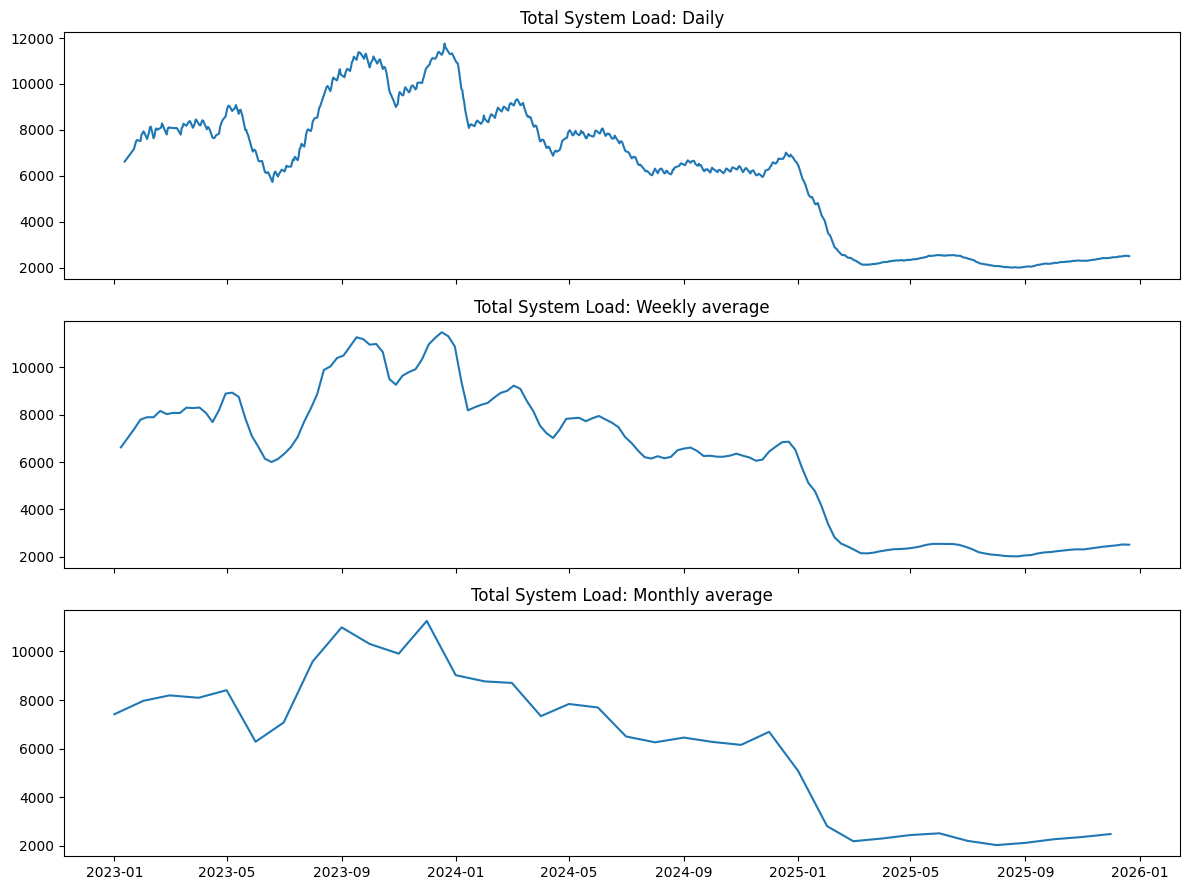

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, t) in zip(axes, [("Daily", d), ("Weekly average", w), ("Monthly average", m)]):
    ax.plot(t.index, t["total_system_load"])
    ax.set_title(f"Total System Load: {name}")
plt.tight_layout()

In [5]:
m[["total_system_load", "hhs_care", "net_daily_intake", "apprehended", "reported_days"]].round(0)

,total_system_load,hhs_care,net_daily_intake,apprehended,reported_days
period_start,,,,,
2023-01-01,7414.0,7370.0,-198.0,31.0,8
2023-02-01,7967.0,7796.0,-134.0,99.0,19
2023-03-01,8190.0,7945.0,-104.0,130.0,19
2023-04-01,8093.0,7843.0,-81.0,149.0,21
2023-05-01,8404.0,8187.0,-120.0,125.0,22
2023-06-01,6282.0,6136.0,-81.0,89.0,20
2023-07-01,7073.0,6828.0,-24.0,136.0,21
2023-08-01,9585.0,9348.0,-144.0,138.0,20
2023-09-01,10992.0,10701.0,-136.0,168.0,19


In [6]:
tl = m["total_system_load"]
mom = (tl.pct_change() * 100).dropna()
print("peak:", tl.idxmax().date(), round(tl.max()))
print("low :", tl.idxmin().date(), round(tl.min()))
print("rising months:", (mom > 0).sum(), " falling months:", (mom < 0).sum())
print(mom.nlargest(3).round(1))
print(mom.nsmallest(3).round(1))

peak: 2023-12-01 11255
low : 2025-08-01 2027
rising months: 17  falling months: 18
period_start
2023-08-01    35.5
2023-09-01    14.7
2023-12-01    13.6
Name: total_system_load, dtype: float64
period_start
2025-02-01   -44.8
2023-06-01   -25.2
2025-01-01   -24.1
Name: total_system_load, dtype: float64
